> Versión de portafolio. Se conservan las salidas históricas del trabajo académico. Las rutas absolutas de datos, cuando existían, se sustituyeron por nombres locales. Esta versión no se ha ejecutado de nuevo; consulte README y DATOS.md antes de reproducir.


# Proyecto empresa aliada · Entregable 6
## Pronóstico de ventas nacionales de Vanish y Lysol
**Javier Bueno Sánchez** · Ciencia de Datos · EBAC

Objetivo: estimar las ventas futuras en volumen reportado, comparar alternativas y cuantificar sus errores fuera de muestra. El horizonte corresponde a los tres meses completos posteriores al cierre histórico, **agosto–octubre de 2023**; no es una estimación de ventas de 2026.

El código utiliza los cinco archivos originales. Colocarlos en la misma carpeta del Notebook o en una subcarpeta `upload`. Dependencias: Python, pandas, numpy, matplotlib, scikit-learn y openpyxl. Las salidas están ejecutadas. No se requieren descargas ni conexión a Internet.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
import hashlib, platform, sklearn
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 150)
plt.rcParams.update({'figure.figsize':(11,4), 'axes.spines.top':False, 'axes.spines.right':False, 'axes.prop_cycle':plt.cycler(color=['#3A7BD5','#263238','#6E7A89','#56A98C'])})
BASE = Path('upload') if Path('upload').is_dir() else Path('.')
files = {'sales':'FACT_SALES(1).csv','product':'DIM_PRODUCT(1).xlsx','calendar':'DIM_CALENDAR (4)(1).xlsx','category':'DIM_CATEGORY(1).csv','segment':'DIM_SEGMENT(1).xlsx'}
sales=pd.read_csv(BASE/files['sales'], dtype={'ITEM_CODE':str})
product=pd.read_excel(BASE/files['product'],dtype={'ITEM':str})
calendar=pd.read_excel(BASE/files['calendar'])
category=pd.read_csv(BASE/files['category'])
segment=pd.read_excel(BASE/files['segment'])
print('Python',platform.python_version(),'| pandas',pd.__version__,'| sklearn',sklearn.__version__)
for name,f in files.items():
    print(name, hashlib.sha256((BASE/f).read_bytes()).hexdigest())
print('Filas:', {k:len(v) for k,v in [('ventas',sales),('productos',product),('calendario',calendar),('categorías',category),('segmentos',segment)]})

Python 3.12.14 | pandas 2.2.3 | sklearn 1.8.0
sales 711aec27d4d928a2df86ec92c61c78d96d647cf8deddf7218bbe42f399ba1943
product 2d69ba7b54c39ba060f350c9f329239a90e188ba833636c88b93ba503d29d302
calendar 797f5d42475f8c23fc6c6f1a75cb47239c1300cfdeda00d5ed07c9978be3bb7b
category 629da78ab9e388f526799c424b48b0217f40d6af5898b42d2180c564370eca00
segment 8fa8aaf4c235ded4ffa984bab6f6f5507b056f51f656ea95f62eba68d882f03d
Filas: {'ventas': 122002, 'productos': 505, 'calendario': 156, 'categorías': 5, 'segmentos': 53}


## 1. Preparación y control de calidad
La llave del hecho es semana–producto–región. Las dimensiones de producto y calendario se unen con validación muchos a uno. Categorías y segmentos se inspeccionan, pero no son predictores: no aportan valores futuros independientes para estas series agregadas. No se suman promedios semanales por producto.

Se modela `TOTAL_UNIT_SALES`: conserva la escala original porque no existe un diccionario que confirme si son unidades, miles u otra conversión. No se presenta como pesos. `TOTAL_VALUE_SALES` no se utiliza como predictor: su valor futuro sería desconocido y podría introducir fuga de información.

In [2]:
assert not sales.duplicated(['WEEK','ITEM_CODE','REGION']).any()
print('Productos sin llave excluidos de la dimensión:', int(product.ITEM.isna().sum()))
product=product.dropna(subset=['ITEM']).copy()
assert product.ITEM.is_unique and calendar.WEEK.is_unique
assert not sales.isna().any().any()
assert (sales[['TOTAL_UNIT_SALES','TOTAL_VALUE_SALES']]>=0).all().all()
df=sales.merge(product, left_on='ITEM_CODE',right_on='ITEM',how='left',validate='many_to_one',indicator=True)
assert df['_merge'].eq('both').all()
df=df.drop(columns='_merge').merge(calendar,on='WEEK',how='left',validate='many_to_one')
assert df.DATE.notna().all()
print('Regiones y registros:'); print(sales.REGION.value_counts().to_string())
print('Categorías:'); print(category.to_string(index=False))
print('Segmentos:',segment.shape, '| atributos:',segment.columns.tolist())
df['FAMILIA']=np.select([df.BRAND.str.startswith('VANISH'),df.BRAND.eq('LYSOL')],['VANISH','LYSOL'],default='OTRAS')
selected=df[df.REGION.eq('TOTAL AUTOS SCANNING MEXICO') & df.FAMILIA.isin(['VANISH','LYSOL'])].copy()
print('Marcas incluidas:'); print(selected.groupby(['FAMILIA','BRAND']).ITEM.nunique().to_string())
weekly=selected.groupby(['DATE','FAMILIA']).TOTAL_UNIT_SALES.sum().unstack().sort_index()
assert len(weekly)==80 and weekly.notna().all().all()
print('Cobertura:',weekly.index.min(), 'a',weekly.index.max())
print('Separación entre fechas:',weekly.index.to_series().diff().value_counts().to_dict())
print('Resumen:'); print(weekly.describe().round(3).to_string())

Productos sin llave excluidos de la dimensión: 2
Regiones y registros:
REGION
TOTAL AUTOS SCANNING MEXICO    20990
TOTAL AUTOS AREA 2             18505
TOTAL AUTOS AREA 4             17182
TOTAL AUTOS AREA 6             16913
TOTAL AUTOS AREA 3             16496
TOTAL AUTOS AREA 5             16135
TOTAL AUTOS AREA 1             15781
Categorías:
 ID_CATEGORY                       CATEGORY
           1 FABRIC TREATMENT and SANIT\r\n
           2                      AIR CARE 
           3                   LAVAVAJILLAS
           4               MEGA SUPERFICIES
           5            LAVATORY CARE & BRC
Segmentos: (53, 6) | atributos: ['CATEGORY', 'ATTR1', 'ATTR2', 'ATTR3', 'FORMAT', 'SEGMENT']
Marcas incluidas:
FAMILIA  BRAND 
LYSOL    LYSOL      8
VANISH   VANISH    77
Cobertura: 2022-01-09 00:00:00 a 2023-07-17 00:00:00
Separación entre fechas: {Timedelta('7 days 00:00:00'): 78, Timedelta('8 days 00:00:00'): 1}
Resumen:
FAMILIA   LYSOL   VANISH
count    80.000   80.000
mean      3

**Decisiones de limpieza.** No se detectan duplicados de llave, nulos en el hecho ni valores negativos; no se eliminan ventas. Se excluyen dos filas de la dimensión de productos sin código ITEM; ninguna venta queda sin correspondencia. Las ausencias de un SKU no se interpretan individualmente como ventas cero: el objetivo es el total observado de cada familia, presente en las 80 semanas. Los cambios de surtido pueden afectar la interpretación.

El calendario original tiene un salto de ocho días al cambiar de año. Se preservan las fechas de origen y se modela el orden de las semanas con un índice entero; no se interpolan ventas ni se inventa una semana adicional. Se recomienda corregir el calendario con la fuente antes de operar el modelo.

## 2. Exploración y elección de técnica
Se reservan las **últimas 12 semanas** como prueba final antes de explorar patrones para decidir el modelo. Las primeras 68 forman el desarrollo. La selección utiliza tres cortes expansivos dentro de esas 68 semanas: 40→12, 48→12 y 56→12. Los cortes se solapan parcialmente; sus errores no son observaciones independientes.

Se elige **regresión Ridge con rezagos** como candidato predictivo: permite estimar ventas a partir de la historia disponible, controlar la complejidad y producir pronósticos recursivos sin necesitar precios o promociones futuras. Se comparan persistencia, media móvil y regresión de tendencia. Con apenas 80 semanas totales y menos de dos ciclos anuales, no se impone una estacionalidad anual SARIMA. El valor de la complejidad debe demostrarse en validación.

Desarrollo: 2022-01-09 2023-04-24 68
Prueba: 2023-05-01 2023-07-17 12
LYSOL | media primeras 12: 5.064 | últimas 12: 2.735 | autocorrelación lag 1: 0.86
VANISH | media primeras 12: 319.285 | últimas 12: 360.165 | autocorrelación lag 1: 0.24


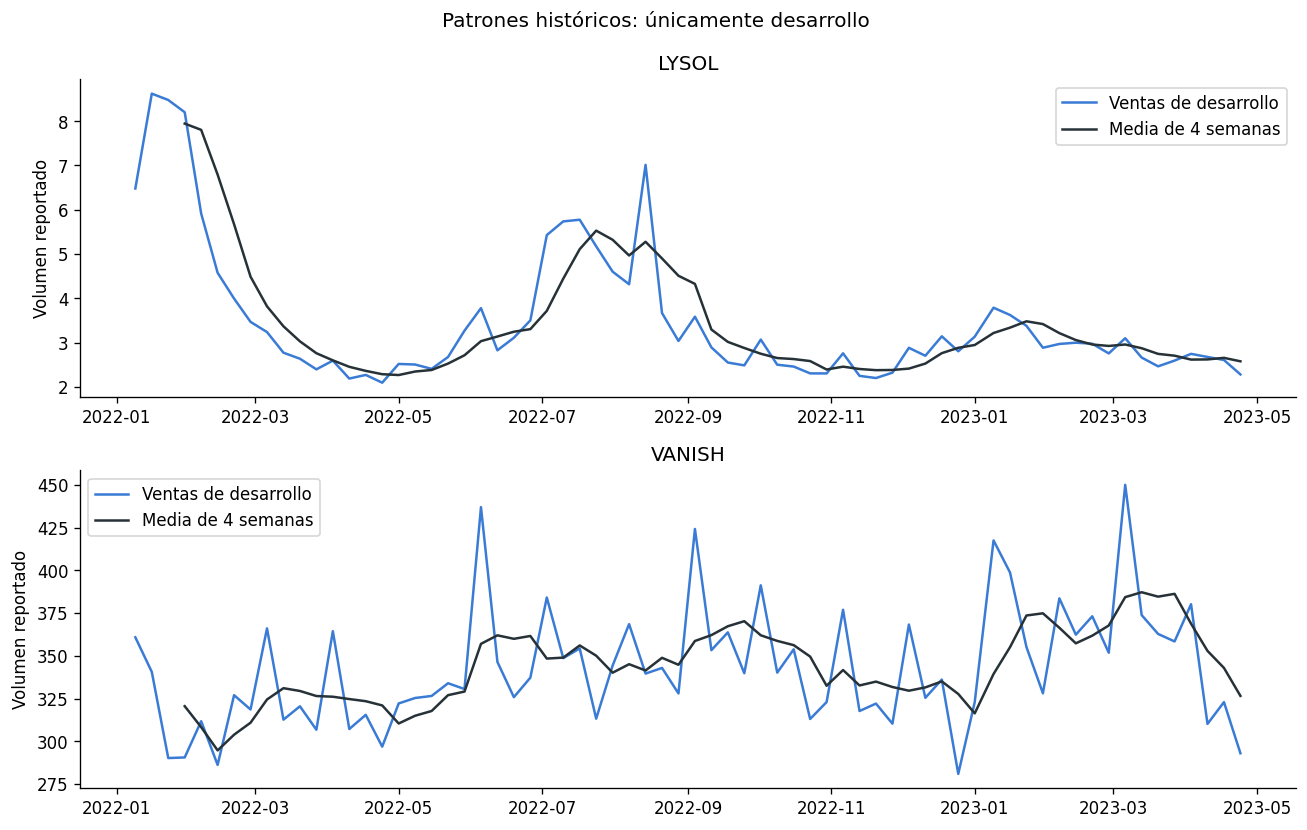

In [3]:
train=weekly.iloc[:-12].copy(); test=weekly.iloc[-12:].copy()
print('Desarrollo:',train.index.min().date(),train.index.max().date(),len(train))
print('Prueba:',test.index.min().date(),test.index.max().date(),len(test))
fig,axs=plt.subplots(2,1,figsize=(11,7))
for ax,b in zip(axs,train.columns):
    ax.plot(train.index,train[b],label='Ventas de desarrollo')
    ax.plot(train.index,train[b].rolling(4).mean(),label='Media de 4 semanas')
    ax.set(title=b,ylabel='Volumen reportado');ax.legend()
fig.suptitle('Patrones históricos: únicamente desarrollo');plt.tight_layout();plt.show()
for b in train:
    print(b, '| media primeras 12:',round(train[b].iloc[:12].mean(),3),'| últimas 12:',round(train[b].iloc[-12:].mean(),3),'| autocorrelación lag 1:',round(train[b].autocorr(1),3))

**Lectura de los patrones de desarrollo.** Lysol pasa de una media de 5.064 en las primeras 12 semanas a 2.735 en las últimas 12, con autocorrelación de primer rezago de 0.86: hay persistencia y una caída de nivel. Vanish pasa de 319.285 a 360.165, con autocorrelación de 0.24 y picos visibles. Esto justifica probar memoria reciente y una tendencia, pero no asumir que la tendencia se prolongará indefinidamente. La validación decidirá si los rezagos aportan valor.


## 3. Modelos, optimización y validación temporal
La regresión usa tiempo, rezagos 1, 2 y 4, y media de las cuatro semanas anteriores. Se estandarizan las variables dentro de cada entrenamiento y se prueban penalizaciones α = 0.1, 1, 10 y 100. La tendencia utiliza solamente el índice temporal. Cada pronóstico de varios pasos se construye recursivamente: las ventas reales de las semanas futuras no entran en sus características.

Se selecciona por **MAE medio de validación**, con RMSE complementario. La prueba final se consulta una sola vez después de fijar el candidato. El MAPE se calcula solo para ventas reales distintas de cero; WAPE compara el error absoluto con el volumen total. No se usa R² como criterio de pronóstico.

In [4]:
def features(history,t):
    return [t,history[-1],history[-2],history[-4],np.mean(history[-4:])]

def forecast(y,h,kind,alpha=1):
    y=np.asarray(y,dtype=float); n=len(y)
    if kind=='ultimo': return np.repeat(y[-1],h)
    if kind=='media4': return np.repeat(y[-4:].mean(),h)
    if kind=='tendencia':
        model=make_pipeline(StandardScaler(),Ridge(alpha=alpha))
        model.fit(np.arange(n).reshape(-1,1),y)
        return np.maximum(0,model.predict(np.arange(n,n+h).reshape(-1,1)))
    X=np.array([features(y[:t],t) for t in range(4,n)])
    model=make_pipeline(StandardScaler(),Ridge(alpha=alpha))
    model.fit(X,y[4:]); hist=list(y); result=[]
    for t in range(n,n+h):
        pred=max(0,float(model.predict([features(hist,t)])[0]))
        hist.append(pred);result.append(pred)
    return np.array(result)

def metrics(actual,pred):
    a=np.asarray(actual);p=np.asarray(pred);mask=a!=0
    return {'MAE':mean_absolute_error(a,p),'MSE':mean_squared_error(a,p),'RMSE':np.sqrt(mean_squared_error(a,p)),
            'MAPE_%':np.mean(np.abs((a[mask]-p[mask])/a[mask]))*100 if mask.any() else np.nan,
            'WAPE_%':np.abs(a-p).sum()/np.abs(a).sum()*100}

candidates={'Último valor':('ultimo',1),'Media 4 semanas':('media4',1),'Tendencia':('tendencia',1)}
candidates.update({f'Ridge α={a}':('ridge',a) for a in [0.1,1,10,100]})
rows=[]
for b in train:
    for name,(kind,alpha) in candidates.items():
        for origin in [40,48,56]:
            pred=forecast(train[b].iloc[:origin],12,kind,alpha)
            rows.append({'Familia':b,'Modelo':name,'Corte':origin,**metrics(train[b].iloc[origin:origin+12],pred)})
cv=pd.DataFrame(rows)
ranking=cv.groupby(['Familia','Modelo'])[['MAE','RMSE']].mean().reset_index().sort_values(['Familia','MAE'])
chosen=ranking.groupby('Familia',sort=False).first()['Modelo'].to_dict()
print(ranking.round(4).to_string(index=False));print('Selección congelada:',chosen)
print('Impacto del ajuste respecto a Ridge α=1 (MAE de validación):')
for b in train:
    r=ranking[ranking.Familia.eq(b)].set_index('Modelo')
    print(b, 'Ridge α=1:',round(r.loc['Ridge α=1','MAE'],4),'→ elegido:',chosen[b],round(r.loc[chosen[b],'MAE'],4))

Familia          Modelo     MAE    RMSE
  LYSOL    Último valor  0.2699  0.3365
  LYSOL     Ridge α=100  0.5314  0.5813
  LYSOL Media 4 semanas  0.5551  0.6033
  LYSOL       Tendencia  0.6557  0.6970
  LYSOL      Ridge α=10  0.6797  0.7277
  LYSOL       Ridge α=1  0.7482  0.8059
  LYSOL     Ridge α=0.1  0.7568  0.8171
 VANISH     Ridge α=100 29.9687 36.6285
 VANISH      Ridge α=10 32.2753 40.4897
 VANISH Media 4 semanas 32.4147 40.9949
 VANISH    Último valor 32.5920 38.9209
 VANISH       Tendencia 33.9227 42.0797
 VANISH       Ridge α=1 34.7763 43.0812
 VANISH     Ridge α=0.1 35.3312 43.6230
Selección congelada: {'LYSOL': 'Último valor', 'VANISH': 'Ridge α=100'}
Impacto del ajuste respecto a Ridge α=1 (MAE de validación):
LYSOL Ridge α=1: 0.7482 → elegido: Último valor 0.2699
VANISH Ridge α=1: 34.7763 → elegido: Ridge α=100 29.9687


## 4. Evaluación final fuera de muestra
El candidato fijado se enfrenta a las últimas 12 semanas desde un único origen. Se incluye el último valor como referencia, sin cambiar la selección tras observar la prueba. Una mejora en validación puede no repetirse en prueba; se informa esa diferencia expresamente.

Familia                  Modelo     MAE       MSE    RMSE  MAPE_%  WAPE_%
  LYSOL            Último valor  0.1884    0.0672  0.2592  7.3560  7.8789
  LYSOL Referencia último valor  0.1884    0.0672  0.2592  7.3560  7.8789
 VANISH             Ridge α=100 32.6604 1661.1545 40.7573  8.7820  8.9913
 VANISH Referencia último valor 70.2598 6389.6324 79.9352 18.4609 19.3424
LYSOL: cambio del MAE respecto a referencia: 0.00% (positivo = mejora).
VANISH: cambio del MAE respecto a referencia: 53.51% (positivo = mejora).
Errores reales − predicción:
            LYSOL   VANISH
DATE                      
2023-05-01 -0.005  -47.177
2023-05-08  0.305   34.509
2023-05-15 -0.152  -33.009
2023-05-22  0.121   18.833
2023-05-29 -0.022  -20.343
2023-06-05  0.639  101.741
2023-06-12 -0.108   14.769
2023-06-19 -0.060   17.800
2023-06-26 -0.115    8.006
2023-07-03  0.056   41.060
2023-07-10  0.390   43.589
2023-07-17  0.288   11.089
Sesgo medio:
LYSOL      0.1114
VANISH    15.9054


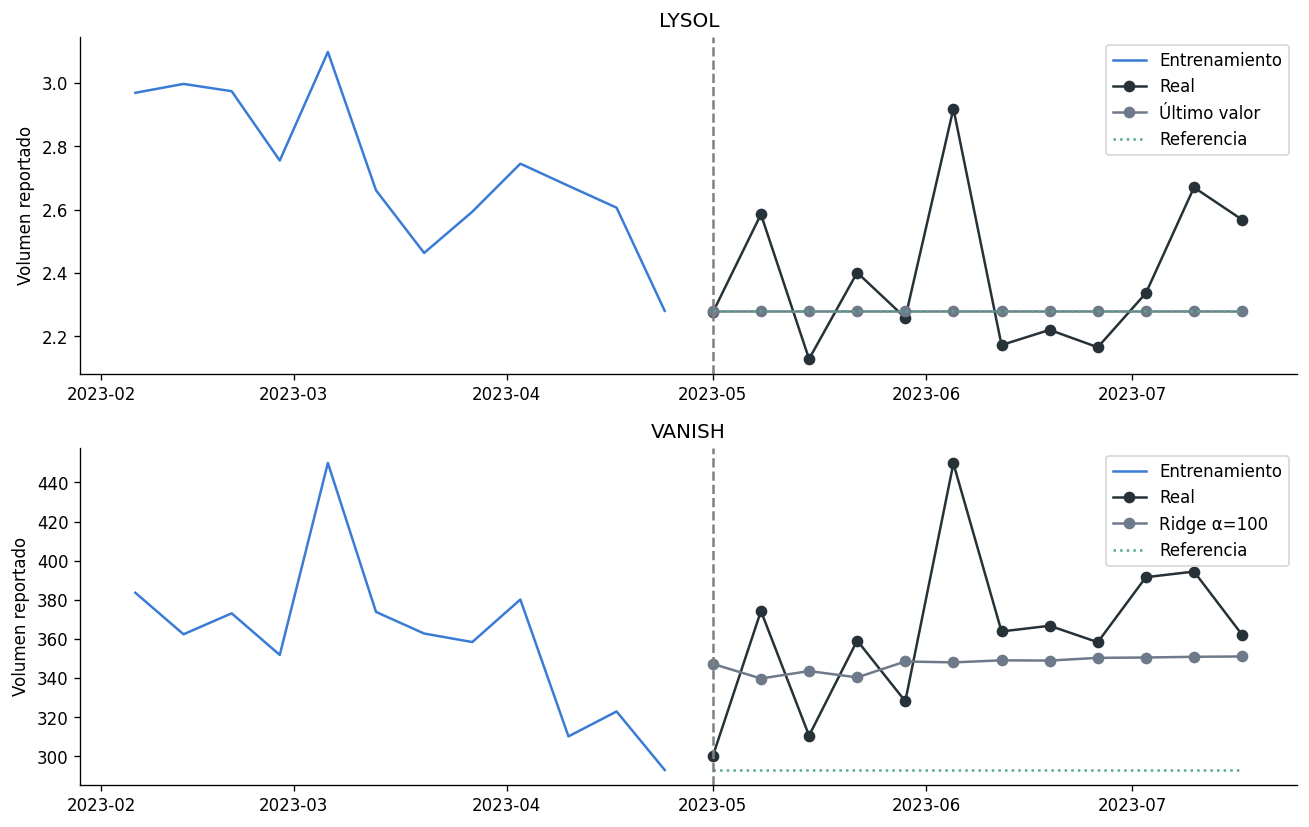

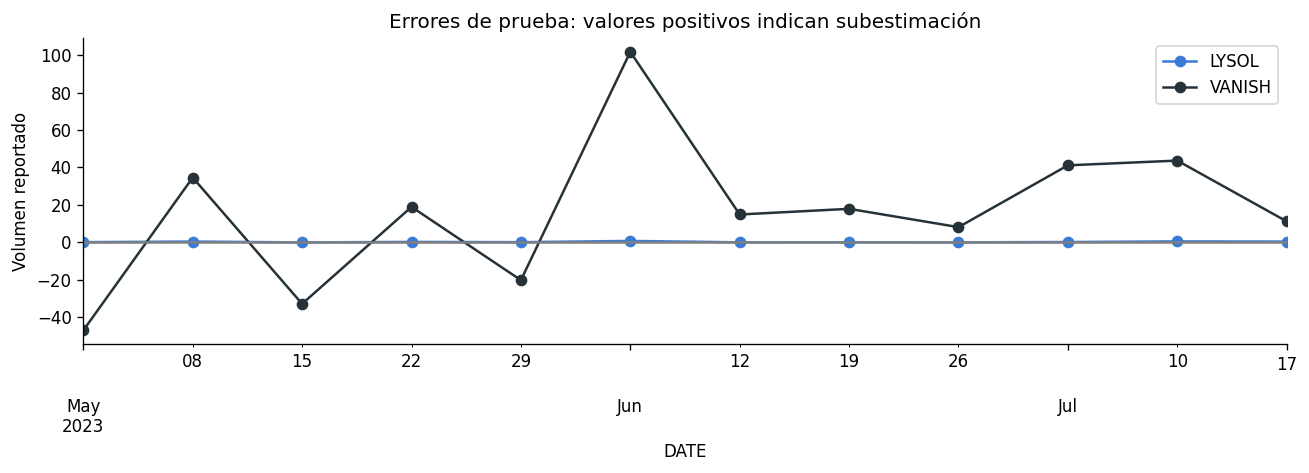

In [5]:
scores=[];predictions={}
fig,axs=plt.subplots(2,1,figsize=(11,7))
for ax,b in zip(axs,train):
    kind,alpha=candidates[chosen[b]]
    pred=forecast(train[b],len(test),kind,alpha);predictions[b]=pred
    scores.append({'Familia':b,'Modelo':chosen[b],**metrics(test[b],pred)})
    baseline=forecast(train[b],len(test),'ultimo')
    scores.append({'Familia':b,'Modelo':'Referencia último valor',**metrics(test[b],baseline)})
    ax.plot(train.index[-12:],train[b].iloc[-12:],label='Entrenamiento')
    ax.plot(test.index,test[b],label='Real',marker='o')
    ax.plot(test.index,pred,label=chosen[b],marker='o')
    ax.plot(test.index,baseline,label='Referencia',linestyle=':')
    ax.axvline(test.index[0],color='gray',linestyle='--');ax.set(title=b,ylabel='Volumen reportado');ax.legend()
plt.tight_layout();plt.show()
score=pd.DataFrame(scores); print(score.round(4).to_string(index=False))
for b in train:
    r=score[score.Familia.eq(b)]
    improvement=100*(1-r.iloc[0].MAE/r.iloc[1].MAE)
    print(f'{b}: cambio del MAE respecto a referencia: {improvement:.2f}% (positivo = mejora).')
residuals=pd.DataFrame({b:test[b].values-predictions[b] for b in train},index=test.index)
print('Errores reales − predicción:'); print(residuals.round(3).to_string())
print('Sesgo medio:'); print(residuals.mean().round(4).to_string())
residuals.plot(marker='o',title='Errores de prueba: valores positivos indican subestimación');plt.axhline(0,color='gray');plt.ylabel('Volumen reportado');plt.tight_layout();plt.show()

## 5. Reentrenamiento y pronóstico futuro
Se mantiene la selección y se reentrena con las 80 semanas. Se predicen las semanas puente restantes de julio y los tres meses completos siguientes: agosto, septiembre y octubre de 2023. Las sumas mensuales asignan cada semana al mes de su fecha del calendario; no son un prorrateo diario. Octubre tiene cinco fechas semanales: comparar totales mensuales exige considerar esa exposición.

La validación cubre horizontes de 12 semanas; el extremo final del pronóstico supera ese horizonte y tiene mayor incertidumbre. No se presentan intervalos de confianza sin una calibración defendible. Los errores históricos ayudan a dimensionar riesgo, pero no constituyen límites probabilísticos.

Pronóstico semanal (incluye puente de julio):
            LYSOL   VANISH
Fecha                     
2023-07-24  2.568  361.395
2023-07-31  2.568  364.365
2023-08-07  2.568  364.325
2023-08-14  2.568  359.640
2023-08-21  2.568  359.391
2023-08-28  2.568  359.643
2023-09-04  2.568  359.673
2023-09-11  2.568  359.112
2023-09-18  2.568  359.193
2023-09-25  2.568  359.353
2023-10-02  2.568  359.516
2023-10-09  2.568  359.609
2023-10-16  2.568  359.800
2023-10-23  2.568  360.005
2023-10-30  2.568  360.217
Pronóstico mensual:
          LYSOL    VANISH  Semanas
Fecha                             
2023-08  10.272  1442.999        4
2023-09  10.272  1437.331        4
2023-10  12.840  1799.147        5


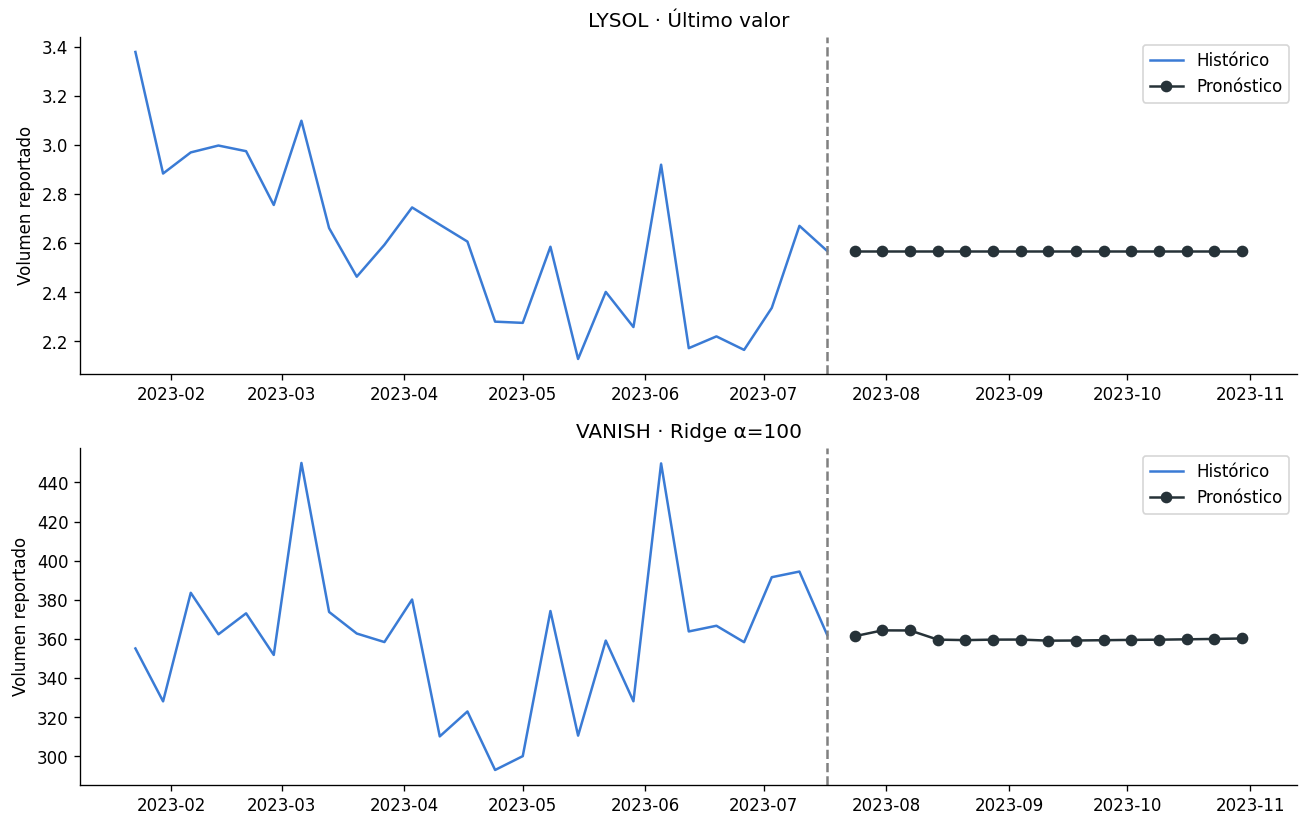

In [6]:
last=weekly.index[-1]
future_dates=pd.date_range(last+pd.Timedelta(days=7),pd.Timestamp('2023-10-31'),freq='7D')
future=pd.DataFrame(index=future_dates)
for b in weekly:
    kind,alpha=candidates[chosen[b]]
    future[b]=forecast(weekly[b],len(future_dates),kind,alpha)
future.index.name='Fecha'
print('Pronóstico semanal (incluye puente de julio):');print(future.round(3).to_string())
full=future.loc['2023-08-01':'2023-10-31']
monthly=full.groupby(full.index.to_period('M')).sum()
counts=full.groupby(full.index.to_period('M')).size()
print('Pronóstico mensual:');print(monthly.assign(Semanas=counts).round(3).to_string())
fig,axs=plt.subplots(2,1,figsize=(11,7))
for ax,b in zip(axs,weekly):
    ax.plot(weekly.index[-26:],weekly[b].iloc[-26:],label='Histórico')
    ax.plot(future.index,future[b],label='Pronóstico',marker='o')
    ax.axvline(last,color='gray',linestyle='--');ax.set(title=f'{b} · {chosen[b]}',ylabel='Volumen reportado');ax.legend()
plt.tight_layout();plt.show()

## 6. Conclusiones y recomendaciones basadas en resultados
Las siguientes conclusiones se calculan a partir de las métricas ejecutadas, para mantener coherencia entre cifras y explicación.

In [7]:
for b in weekly:
    r=score[score.Familia.eq(b)]
    selected_score=r.iloc[0]; ref=r.iloc[1]
    verdict='superó' if selected_score.MAE < ref.MAE else 'no superó'
    print(f'\n{b}: {chosen[b]} {verdict} la referencia en prueba. MAE={selected_score.MAE:.3f}, RMSE={selected_score.RMSE:.3f}, WAPE={selected_score["WAPE_%"]:.2f}%.')
    print('Pronósticos mensuales:', '; '.join(f'{m}: {v:.3f}' for m,v in monthly[b].items()))
    print('Promedio semanal esperado por mes:', '; '.join(f'{m}: {v:.3f}' for m,v in (monthly[b]/counts).items()))
    if selected_score.MAE>=ref.MAE:
        print('Recomendación: conservar el modelo como ejercicio validado, pero exigir nueva evidencia antes de sustituir la referencia operativa.')
    else:
        print('Recomendación: usar como apoyo provisional de planificación y comprobar el desempeño en las siguientes semanas.')


LYSOL: Último valor no superó la referencia en prueba. MAE=0.188, RMSE=0.259, WAPE=7.88%.
Pronósticos mensuales: 2023-08: 10.272; 2023-09: 10.272; 2023-10: 12.840
Promedio semanal esperado por mes: 2023-08: 2.568; 2023-09: 2.568; 2023-10: 2.568
Recomendación: conservar el modelo como ejercicio validado, pero exigir nueva evidencia antes de sustituir la referencia operativa.

VANISH: Ridge α=100 superó la referencia en prueba. MAE=32.660, RMSE=40.757, WAPE=8.99%.
Pronósticos mensuales: 2023-08: 1442.999; 2023-09: 1437.331; 2023-10: 1799.147
Promedio semanal esperado por mes: 2023-08: 360.750; 2023-09: 359.333; 2023-10: 359.829
Recomendación: usar como apoyo provisional de planificación y comprobar el desempeño en las siguientes semanas.


**Qué demuestran los datos.** Las métricas anteriores cuantifican errores sobre 12 semanas no utilizadas para seleccionar ni entrenar el modelo. No garantizan desempeño en otro periodo ni permiten atribuir causas a los cambios de ventas.

**Qué sostiene el modelo.** El pronóstico depende de la continuidad del patrón reciente y de la cobertura del canal nacional observado. Los modelos recursivos pueden suavizar picos y acumular error. Las ventas registradas no equivalen a demanda no restringida cuando existen faltantes de inventario.

**Qué investigar.** Confirmar la escala de ventas y el calendario, incorporar promociones, precio, disponibilidad y cambios de surtido; reunir más ciclos antes de estimar estacionalidad anual. La base no permite interpretar estas cifras como ventas de todo el mercado mexicano.

**Cómo validar y actuar.** Actualizar semanalmente, comparar cada cierre con la referencia y revisar MAE, WAPE y sesgo. Evaluar de nuevo con orígenes móviles sin reutilizar este test para ajustar parámetros. Usar los volúmenes como insumo de compras y capacidad, condicionados a inventario y plazos; no convertirlos directamente en stock de seguridad sin estudiar el nivel de servicio y los errores por horizonte.

**Cumplimiento de la actividad:** carga y preparación, elección justificada, separación temporal, entrenamiento, ajuste documentado, métricas y gráficos de prueba, pronóstico de tres meses y recomendaciones incluidos.